# 05 – Lag features: using past sales without seeing the future

Calendar features (notebook 04) tell the model *what kind of day* it is. **Lag features** tell it *how much this
series usually sells*: its sales some days ago, recent averages, its weekday pattern.

They are the most useful features in forecasting, and the most dangerous: built carelessly, they leak
the future (remember the `shift(1)` trap in notebook 02).

**Plan:**
1. The 16-day rule, and what it costs us.
2. The lag features in `src/lags.py`, and how good each one is on its own.
3. Testing for leakage.
4. The full feature table for the model.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.baselines import level_and_weekday
from src.data import load_train
from src.dataset import build_table
from src.features import load_holidays, load_stores
from src.lags import full_calendar, lag_features
from src.metrics import rmsle
from src.validation import backtest, make_cutoffs

IMAGES = "../images"

train = load_train()
wide = train.pivot_table(index="date", columns=["store_nbr", "family"], values="sales", observed=True)

## 1. The 16-day rule

We make all 16 forecasts on the same day, the **cutoff** (for Kaggle: 15 August 2017). So:
- for the **1st** forecast day (16 August), the newest known sales are **1 day** old;
- for the **16th** forecast day (31 August), the newest known sales are **16 days** old.

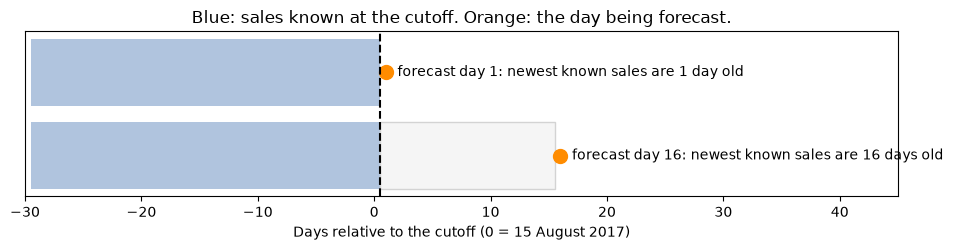

In [2]:
# x axis: days relative to the cutoff (0 = 15 August, the last day with known sales)
fig, ax = plt.subplots(figsize=(10, 2.6))
for row, day in enumerate([16, 1]):
    ax.barh(row, 30, left=-29.5, color="lightsteelblue")                                   # known sales
    if day > 1:
        ax.barh(row, day - 1, left=0.5, color="whitesmoke", edgecolor="lightgrey")         # not known yet
    ax.plot(day, row, "o", color="darkorange", markersize=10)                              # the day forecast
    ax.text(day + 1, row, f"forecast day {day}: newest known sales are {day} day{'s' if day > 1 else ''} old",
            va="center")
ax.axvline(0.5, color="black", linestyle="--")
ax.set_yticks([])
ax.set_xlim(-30, 45)
ax.set_xlabel("Days relative to the cutoff (0 = 15 August 2017)")
ax.set_title("Blue: sales known at the cutoff. Orange: the day being forecast.")
fig.tight_layout()
fig.savefig(f"{IMAGES}/sixteen_day_rule.png", dpi=120)
plt.show()

There are two ways to build lag features from this:

| Approach | Idea | + | − |
|---|---|---|---|
| **A. One rule for all days** | Every feature uses sales at least 16 days old | One feature table, one model, leakage impossible by construction | Throws away fresher data for the first forecast days |
| B. Features at the cutoff | Each forecast day uses everything up to the cutoff | Uses all the data | Training data must be built "as of" many cutoffs, more complex |

We start with **A**, the simpler one. But simplicity has a price, and we should know how big it is before choosing.
Our best rule, level + weekday (notebook 03), always used data up to the cutoff (approach B).
We can rebuild the same rule from 16-day-old data only (approach A) and backtest both on the same 8 windows.

In [3]:
features = lag_features(wide)

# The same rule from 16-day-old data: level = mean_14, weekday adjustment = same weekday (8 weeks) - 56-day mean.
# (All on the log scale, so the adjustment is added; expm1 converts back to sales.)
rule_from_lags = np.expm1(features["mean_14"] + features["same_weekday_mean_8"] - features["mean_56"]).clip(lower=0)
rule_from_lags = rule_from_lags.unstack(["store_nbr", "family"])  # back to wide: dates x series

cutoffs = make_cutoffs(wide.index.max(), n_windows=8)
comparison = backtest(wide, {"B: at the cutoff": level_and_weekday}, cutoffs)
comparison["A: 16-day-old data only"] = [
    rmsle(wide.loc[c + pd.Timedelta(days=1): c + pd.Timedelta(days=16)],
          rule_from_lags.loc[c + pd.Timedelta(days=1): c + pd.Timedelta(days=16)])
    for c in cutoffs
]
comparison.loc["mean"] = comparison.mean()
comparison.round(3)

,B: at the cutoff,A: 16-day-old data only
window starts,,
2017-04-10,0.626,0.630
2017-04-26,0.596,0.791
2017-05-12,0.485,0.535
2017-05-28,0.422,0.457
2017-06-13,0.414,0.427
2017-06-29,0.406,0.411
2017-07-15,0.420,0.429
2017-07-31,0.524,0.542
mean,0.487,0.528


**The cost of approach A: about 0.04 RMSLE on average** (0.487 → 0.528). In most windows it's small,
0.005–0.05. One window stands out: late April, 0.596 → 0.791. Why?

In [4]:
store_52 = train[train["store_nbr"] == 52].groupby("date")["sales"].sum()
first_sale = store_52[store_52 > 0].index.min()
print(f"Store 52 first sold something on {first_sale:%Y-%m-%d}")

Store 52 first sold something on 2017-04-20


**Store 52 opened on 20 April 2017.** In the window starting 26 April, approach B knows the store has been open
for 6 days. Approach A only sees sales from 16+ days earlier, when the store was still closed, so it forecasts
about zero for a store that is selling normally. Fresh data matters most **when something changes.**

**Decision:** we keep approach A for now. A model gets things the rule doesn't have (calendar features, patterns
learned across all 1,782 series), so it may make up the 0.04. If it doesn't, step 7 tells us, and approach B
becomes the next improvement.

## 2. The lag features

`lag_features` in `src/lags.py` builds these, all on the log scale `log1p(sales)`:

| Feature | Meaning |
|---|---|
| `lag_16` | Sales 16 days before: the newest day allowed |
| `lag_21`, `lag_28` | Same weekday, 3 and 4 weeks before |
| `lag_364` | Same weekday, 52 weeks before ("same time last year") |
| `mean_7` … `mean_56` | Average of the 7 … 56 days ending 16 days before |
| `same_weekday_mean_4`, `_8` | Average of the same weekday over 4 or 8 weeks (from 3 weeks back) |
| `zero_days_28` | How many of 28 days (ending 16 days before) had zero sales |

One detail first: Christmas Day is missing from the data. Without that row, "16 rows back" would sometimes be
17 days back. `full_calendar` adds the missing days as **NaN** (unknown), not 0: the stores were closed, which
says nothing about demand, and rolling means skip NaN.

In [5]:
print("Rows in wide:", len(wide), " after full_calendar:", len(full_calendar(wide)))
features.loc[(slice("2017-08-09", "2017-08-15"), 44, "GROCERY I"), :].round(2)

Rows in wide: 1684  after full_calendar: 1688


,,,lag_16,lag_21,lag_28,lag_364,mean_7,mean_14,mean_28,mean_56,same_weekday_mean_4,same_weekday_mean_8,zero_days_28
date,store_nbr,family,,,,,,,,,,,
2017-08-09,44,GROCERY I,9.15,9.15,9.03,8.99,9.23,9.21,9.25,9.25,9.13,9.14,0.0
2017-08-10,44,GROCERY I,8.99,8.98,8.83,8.84,9.22,9.21,9.25,9.25,8.92,8.96,0.0
2017-08-11,44,GROCERY I,9.08,9.24,9.16,9.22,9.21,9.22,9.25,9.25,9.22,9.25,0.0
2017-08-12,44,GROCERY I,8.88,9.43,9.51,9.10,9.19,9.22,9.25,9.25,9.56,9.57,0.0
2017-08-13,44,GROCERY I,9.14,9.57,9.58,9.21,9.18,9.22,9.24,9.24,9.67,9.64,0.0
2017-08-14,44,GROCERY I,9.54,9.15,9.27,9.05,9.19,9.22,9.24,9.24,9.23,9.19,0.0
2017-08-15,44,GROCERY I,9.58,8.99,9.08,9.10,9.19,9.22,9.23,9.24,9.03,9.03,0.0


### How good is each feature on its own?

A quick check without a model: use each feature directly as a forecast (it's already on the log scale, so the
error is simply the RMSE between feature and target) and score it on all of 2017.
For comparison we add `lag_1`, yesterday's sales, which our rule does **not** allow: it shows what the
16-day rule costs at the level of single features.

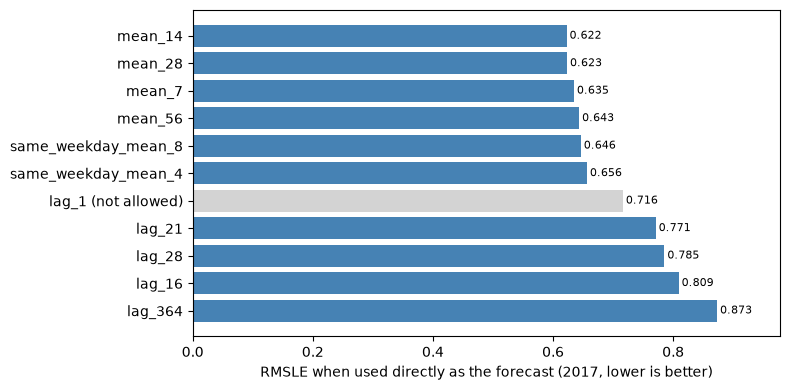

In [6]:
log_sales = np.log1p(full_calendar(wide))
target = np.log1p(wide).stack(["store_nbr", "family"], future_stack=True).rename("target")
in_2017 = features.index.get_level_values("date") >= "2017-01-01"

def score(feature):
    both = pd.concat([feature, target], axis=1, join="inner").dropna()
    return np.sqrt(np.mean((both.iloc[:, 0] - both["target"]) ** 2))

lag_1 = log_sales.shift(1).stack(["store_nbr", "family"], future_stack=True)
single = {"lag_1 (not allowed)": score(lag_1[lag_1.index.get_level_values("date") >= "2017-01-01"])}
for name in ["lag_16", "lag_21", "lag_28", "lag_364", "mean_7", "mean_14", "mean_28", "mean_56",
             "same_weekday_mean_4", "same_weekday_mean_8"]:
    single[name] = score(features.loc[in_2017, name])
single = pd.Series(single).sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
colors = ["lightgrey" if "not allowed" in name else "steelblue" for name in single.index]
ax.barh(single.index[::-1], single.values[::-1], color=colors[::-1])
for y, v in enumerate(single.values[::-1]):
    ax.text(v + 0.005, y, f"{v:.3f}", va="center", fontsize=8)
ax.set_xlabel("RMSLE when used directly as the forecast (2017, lower is better)")
ax.set_xlim(0, single.max() * 1.12)
fig.tight_layout()
fig.savefig(f"{IMAGES}/single_feature_scores.png", dpi=120)
plt.show()

**What we found:**
- **Averages beat single days again.** `mean_14` and `mean_28` are the best single features; any single lag is worse.
- **The 16-day rule costs a lot for single days:** `lag_16` is much worse than `lag_1`. But the 14-day average
  of 16-day-old data beats even `lag_1`: averaging removes more error than freshness adds.
- **Same weekday helps:** `lag_21` (same weekday) beats `lag_16` (a different weekday), although it is older.
- **`lag_364` is the weakest**: a year is a long time for these series (trend, new stores, the shifted
  back-to-school season). It may still help the model at Christmas or for yearly events.

A model will combine all of these, so a weak feature on its own can still help in combination.
`zero_days_28` isn't in the chart because it isn't a forecast, but it lets the model recognise dead series
and closed stores.

## 3. Testing for leakage

The 16-day rule is easy to break by accident: a `shift(1)` instead of `shift(16)`, a rolling window that
ends one day too late. Nothing would crash, the backtest score would just look **better** than it really is.

`tests/test_lags.py` contains a test that works like an experiment:
1. compute the features for some date;
2. change the sales of that date and the 15 days before it to absurd values (1,000,000);
3. compute the features again: **they must be identical.**

If any feature used one of those 15 days, it changes, and the test fails.

**Does the test actually catch leaks?** We checked by planting one: we changed `mean_7` to average the 7 days
up to *yesterday* (`log_sales.shift(1)` instead of `known`). The leakage test failed at once, and passed again
after the line was restored. The demonstration below repeats the experiment on the real data:

In [7]:
date = pd.Timestamp("2017-08-15")
before = lag_features(wide).loc[date]

changed = wide.copy()
changed.loc[date - pd.Timedelta(days=15):] = 1_000_000
after = lag_features(changed).loc[date]

print("Features unchanged after changing the last 15 days:", before.equals(after))

Features unchanged after changing the last 15 days: True


Run all tests with `pytest` in the project folder: there are now 10 (6 for calendar features, 4 for lags).

## 4. The full feature table

`build_table` in `src/dataset.py` joins everything: lag features, calendar features, holiday flags,
and the target `log1p(sales)`. With `end="2017-08-31"` it also creates the 16 test days, whose features are
complete (every lag is at least 16 days old) and whose target is unknown (NaN).

In [8]:
table = build_table(train, load_stores(), load_holidays(), end="2017-08-31")
print(f"{table.shape[0]:,} rows x {table.shape[1]} columns, {table.memory_usage(deep=True).sum() / 1e6:.0f} MB")

test_rows = table.loc[pd.Timestamp("2017-08-16"):]
print(f"Test rows: {len(test_rows):,}, missing feature values: {int(test_rows.drop(columns='target').isna().sum().sum())}")

3,036,528 rows x 23 columns, 389 MB
Test rows: 28,512, missing feature values: 0


In [9]:
# Share of missing values per column
table.isna().mean().loc[lambda s: s > 0].round(3)

lag_16                 0.012
lag_21                 0.015
lag_28                 0.019
lag_364                0.215
mean_7                 0.009
mean_14                0.009
mean_28                0.009
mean_56                0.009
same_weekday_mean_4    0.012
same_weekday_mean_8    0.012
zero_days_28           0.009
target                 0.012
dtype: float64

**Missing values are expected, and each has a reason:**
- `lag_364`: about 21%, because the first year of data has no "year before".
- The other lags: about 1–2%, from the first weeks of 2013 (no history yet) and the missing Christmas days.
- `target`: about 1%: the test days and the Christmas rows.

LightGBM handles NaN in features by itself. In step 7 we will train only on rows with a known target, and probably
skip 2013, where many features are still incomplete.

**One leftover from notebook 01:** the 2016 earthquake. It has its own flag (`earthquake`, step 5), but the lag
features of the following weeks still contain the earthquake spike. Whether to also drop those weeks from training
is a question we can only answer with a model, so it moves to step 7.

## Summary

| Finding | Consequence |
|---|---|
| Every lag is at least 16 days old (approach A) | One table, one model, leakage impossible by construction |
| Approach A costs ~0.04 RMSLE for our best rule, much more when a store just opened | The model must make up for it; approach B is the backup plan |
| Averages are the best single features; same weekday beats a closer different weekday | `mean_14`, `mean_28`, `same_weekday_mean_*` |
| A leakage test catches a planted `shift(1)` | Run `pytest` after every change to the feature code |
| 3 million rows × 23 columns, complete for the test period | Ready for a model |

**Next step (step 7):** train LightGBM on this table, backtest it, and see if it beats 0.487 (our best rule in the
backtest) and 0.41457 (Kaggle). Before that, install the library LightGBM needs on macOS:
`conda install -n store-sales -c conda-forge llvm-openmp`.